## News visits analysis

This part focuses on how we can analyse the success of an article can be studied from the scope AIT. More precisly, we use AIT to try to find correlations beetween the content of the article (titles, bodies, etc) and the user-relative metrics (click, readtime, etc)

### BEFORE FIRST EXECUTION

Please download ebnerd_demo.zip at this adress : https://recsys.eb.dk/ and unzip it in this notebook directory

Please also note that the cell generating the results takes approximately one hour to run. Since a previous run has already generated the results and saved them in complexitys_48h.parquet, you can simply skip this cell and load the existing file instead.

### Imports

*There can be others. If the execution bugs, please add them ><*

In [108]:
import os

import pandas as pd

import lzma

import time
from tqdm.auto import tqdm

import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import roc_auc_score

import statsmodels.formula.api as smf

from functools import lru_cache

from collections import Counter

### Dataset

We use EB-neRD.demo a dataset published by the danish newspaper Ekstra Bladet.
It notably contains archives of more than 10 000 articles, more than half of them with user-relative metrics (total_inviews', 'total_pageviews', 'total_read_time')

In [70]:
# pip install pandas pyarrow
art = pd.read_parquet("articles.parquet")
print(art.shape)
print(art.columns.tolist())
art.head()

(11777, 21)
['article_id', 'title', 'subtitle', 'last_modified_time', 'premium', 'body', 'published_time', 'image_ids', 'article_type', 'url', 'ner_clusters', 'entity_groups', 'topics', 'category', 'subcategory', 'category_str', 'total_inviews', 'total_pageviews', 'total_read_time', 'sentiment_score', 'sentiment_label']


,article_id,title,subtitle,last_modified_time,premium,body,published_time,image_ids,article_type,url,...,entity_groups,topics,category,subcategory,category_str,total_inviews,total_pageviews,total_read_time,sentiment_score,sentiment_label
0,3037230,Ishockey-spiller: Jeg troede jeg skulle dø,ISHOCKEY: Ishockey-spilleren Sebastian Harts h...,2023-06-29 06:20:57,False,Ambitionerne om at komme til USA og spille ish...,2003-08-28 08:55:00,None,article_default,https://ekstrabladet.dk/sport/anden_sport/isho...,...,[],"[Kriminalitet, Kendt, Sport, Katastrofe, Mindr...",142,"[327, 334]",sport,NaN,NaN,NaN,0.9752,Negative
1,3044020,Prins Harry tvunget til dna-test,Hoffet tvang Prins Harry til at tage dna-test ...,2023-06-29 06:21:16,False,Den britiske tabloidavis The Sun fortsætter me...,2005-06-29 08:47:00,"[3097307, 3097197, 3104927]",article_default,https://ekstrabladet.dk/underholdning/udlandke...,...,"[PER, PER]","[Kriminalitet, Kendt, Underholdning, Personfar...",414,[432],underholdning,NaN,NaN,NaN,0.7084,Negative
2,3057622,Rådden kørsel på blå plader,Kan ikke straffes: Udenlandske diplomater i Da...,2023-06-29 06:21:24,False,Slingrende spritkørsel. Grove overtrædelser af...,2005-10-10 07:20:00,[3047102],article_default,https://ekstrabladet.dk/nyheder/samfund/articl...,...,[],"[Kriminalitet, Transportmiddel, Bil]",118,[133],nyheder,NaN,NaN,NaN,0.9236,Negative
3,3073151,Mærsk-arvinger i livsfare,FANGET I FLODBØLGEN: Skibsrederens oldebørn må...,2023-06-29 06:21:38,False,To oldebørn af skibsreder Mærsk McKinney Mølle...,2005-01-04 06:59:00,"[3067474, 3067478, 3153705]",article_default,https://ekstrabladet.dk/nyheder/samfund/articl...,...,[],"[Erhverv, Privat virksomhed, Livsstil, Familie...",118,[133],nyheder,NaN,NaN,NaN,0.9945,Negative
4,3193383,Skød svigersøn gennem babydyne,44-årig kvinde tiltalt for drab på ekssvigersø...,2023-06-29 06:22:57,False,En 44-årig mormor blev i dag fremstillet i et ...,2003-09-15 15:30:00,None,article_default,https://ekstrabladet.dk/krimi/article3193383.ece,...,[],"[Kriminalitet, Personfarlig kriminalitet]",140,[],krimi,NaN,NaN,NaN,0.9966,Negative



We now reformate the dataset and split it into 2 categories:
- full_corpus : contains every article (to encode environment)
- toStudy_corpus : contains only the articles that will be studied statistically

In [71]:
#FULL CORPUS:
cols = ["article_id", "title", "subtitle", "premium", "body", "category_str",
        "published_time", "total_inviews", "total_pageviews", "total_read_time"]
full_corpus = (
    art[cols]
    .copy()
    .assign(published_time=lambda d: pd.to_datetime(d["published_time"]))
    .sort_values("published_time")
    .reset_index(drop=True)
)
# TOSTUDY_CORPUS
toStudy_corpus=  full_corpus.copy()
#       We only keep lines which usage can be analyse
toStudy_corpus = toStudy_corpus.dropna(subset=["total_inviews", "total_pageviews", "total_read_time"])
toStudy_corpus = toStudy_corpus[toStudy_corpus["total_inviews"] > 0]
toStudy_corpus = toStudy_corpus[toStudy_corpus["body"].str.len() > 500]
toStudy_corpus = toStudy_corpus[~toStudy_corpus["premium"]]
#       We also add interesting metrics
toStudy_corpus["ctr"] = toStudy_corpus["total_pageviews"] / toStudy_corpus["total_inviews"]             # Is the article appeling? (people click when they see it)
toStudy_corpus["read_per_view"] = toStudy_corpus["total_read_time"] / toStudy_corpus["total_pageviews"]  # Does people stick to the article?
toStudy_corpus["body_len"] = toStudy_corpus["body"].str.len()

print(len(full_corpus))
print(len(toStudy_corpus))


11777
6322


### Complexities computation

We want now to create functions to compute complexities. For clarity sake and ease of use, we create a python class that encapsulates the corpus operations.

In [72]:
FILTERS = [{"id": lzma.FILTER_LZMA2, "preset": 9, "dict_size": 64 * 2**20}]  # Window 64 Mo
FILTERS_SMALL = [{"id": lzma.FILTER_LZMA2, "preset": 9, "dict_size": 500 * 2**10}]  # 1 MiB window

def complexity(text: str, small_filter=False) -> int:
    if small_filter:
        return len(lzma.compress(text.encode("utf-8"), format=lzma.FORMAT_RAW, filters=FILTERS_SMALL))
    else:
        return len(lzma.compress(text.encode("utf-8"), format=lzma.FORMAT_RAW, filters=FILTERS))


class NewsCorpus:
    def __init__(self, df):
        assert df["article_id"].is_unique
        self.df = df  #We put the date in datetime format and we make sure the articles are sorted by datetime
        self.id2date = self.df.set_index("article_id")["published_time"] 
        self.id2pos = pd.Series(self.df.index, index=self.df["article_id"])
        self.id2body = self.df.set_index("article_id")["body"]
        self.id2title = self.df.set_index("article_id")["title"]
        self._t = self.df["published_time"].values

    def date(self, article_id):
        return self.id2date[article_id]

    def body(self, article_id):
        return self.id2body[article_id]

    def title(self, article_id):
        return self.id2title[article_id]

    def env(self, article_id, hours=48):
        """
        Extract the environment of an article, that is to say the articles that were published in the h hours before the goven article.
        
        The "hours" parameter can be a number or None. In the latter case, all the precedent article will be in the environment
        """
        i = self.id2pos[article_id] 

        if hours is None:
            return self.df.iloc[:i] # all articles before
        else:
            lo = self._t.searchsorted(self._t[i] - pd.Timedelta(hours=hours))
            return self.df.iloc[lo:i]


def complexities(corpus, article_id, hours=48):
    body= corpus.body(article_id)
    title = corpus.title(article_id)
    
    dataset_env = corpus.env(article_id, hours)
    str_env = " ".join(dataset_env["body"].tolist())
    complexity_env = complexity(str_env) #USed to compute C_cond

    C_self= complexity(body)
    C_cond= complexity(str_env + " " +body) - complexity_env

    C_self_title=complexity(title)
    C_cond_title=complexity(str_env + " " +title) - complexity_env
    return {"article_id": article_id,
        "env_n": len(dataset_env), "env_chars": len(str_env),
        "c_self": C_self, "c_cond": C_cond,
        "novelty": C_cond / C_self if C_self else float("nan"),
        "c_self_title": C_self_title, "c_cond_title": C_cond_title,
        "novelty_title": C_cond_title / C_self_title if C_self_title else float("nan")
        }



We can use this new structure on our full_corpus and then test the complexity on the first article

In [73]:
corpus=  NewsCorpus(full_corpus)
first_article_id = toStudy_corpus["article_id"].iloc[0]
t0 = time.time(); print( complexities(corpus, first_article_id) ); print(time.time() - t0, "s")


{'article_id': 9637298, 'env_n': 26, 'env_chars': 52953, 'c_self': 1332, 'c_cond': 912, 'novelty': 0.6846846846846847, 'c_self_title': 24, 'c_cond_title': 9, 'novelty_title': 0.375}
0.15517187118530273 s


We can now generate our results.

In [74]:
rerun = False
if os.path.exists("complexities_48h.parquet") and not rerun:
    res = pd.read_parquet("complexities_48h.parquet")
else:
    res = pd.DataFrame([complexities(corpus, a) for a in tqdm(toStudy_corpus["article_id"])])
    res.to_parquet("complexities_48h.parquet")

### Results analysis

First let's concatenate our results with the rest of the dataset.

In [75]:
res = pd.read_parquet("complexities_48h.parquet")
df = res.merge(toStudy_corpus, on="article_id", how="left")
print(df.shape)

(6322, 21)


#### Metrics analysis

First, we  try to understand how the text-metrics we have calculated are corrolated to the text and the environment themselves. (Typically, how having a big environment or a big body influence the complexities)

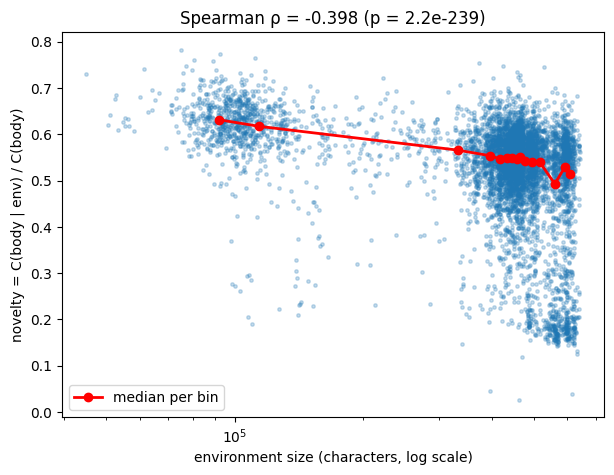

In [76]:
# Novelty and size of the environment

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df["env_chars"], df["novelty"], s=6, alpha=0.25)

med1 = df.groupby(pd.qcut(df["env_chars"], 15, duplicates="drop"), observed=True)[["env_chars", "novelty"]].median()
ax.plot(med1["env_chars"], med1["novelty"], color="red", lw=2, marker="o", label="median per bin")

rho1, p1 = stats.spearmanr(df["env_chars"], df["novelty"])
ax.set_xscale("log")
ax.set_xlabel("environment size (characters, log scale)")
ax.set_ylabel("novelty = C(body | env) / C(body)")
ax.set_title(f"Spearman ρ = {rho1:.3f} (p = {p1:.1e})")
ax.legend()
plt.show()

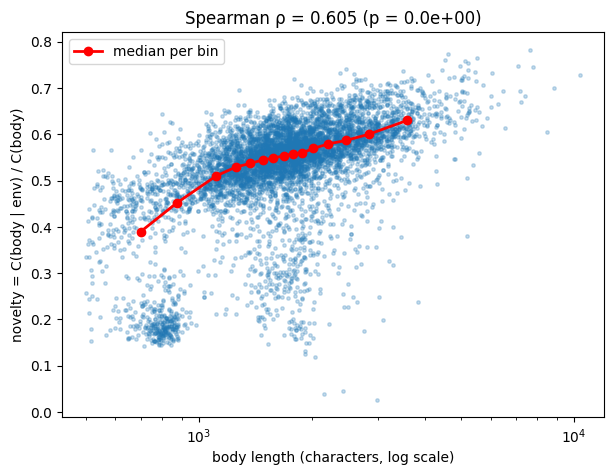

In [77]:
# Novelty and size of the article

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df["body_len"], df["novelty"], s=6, alpha=0.25)

med2 = df.groupby(pd.qcut(df["body_len"], 15, duplicates="drop"), observed=True)[["body_len", "novelty"]].median()
ax.plot(med2["body_len"], med2["novelty"], color="red", lw=2, marker="o", label="median per bin")

rho2, p2 = stats.spearmanr(df["body_len"], df["novelty"])
ax.set_xscale("log")
ax.set_xlabel("body length (characters, log scale)")
ax.set_ylabel("novelty = C(body | env) / C(body)")
ax.set_title(f"Spearman ρ = {rho2:.3f} (p = {p2:.1e})")
ax.legend()
plt.show()

As we could have guessed, we observe 2 phenomena
- The bigger the environment, the less novelty. 
- The smaller the text, the more novelty.

 However, these effects do not necessary have to be compensated as they also impacts the reader.
 - If there is a lot of article in a given span of time, the user is less likely to spend attention on one particular article.
 - If something is short, it is less redundant and mecanically contains more novalty. 

#### First Hypothesis : The articles most visited are those with the most novelty in the title

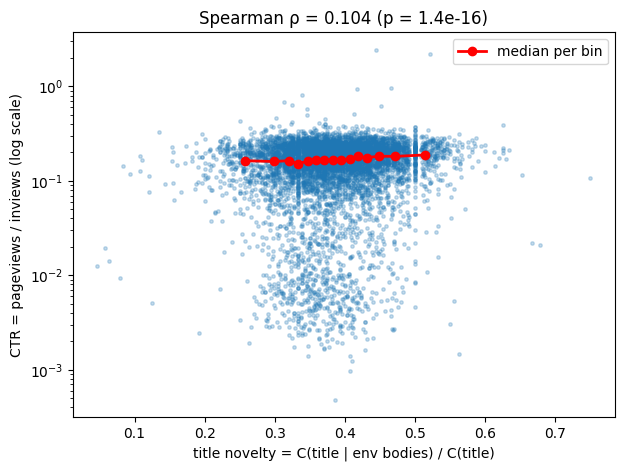

In [105]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df["novelty_title"], df["ctr"], s=6, alpha=0.25)

med = df.groupby(pd.qcut(df["novelty_title"], 15, duplicates="drop"), observed=True)[["novelty_title", "ctr"]].median()
ax.plot(med["novelty_title"], med["ctr"], color="red", lw=2, marker="o", label="median per bin")

rho, p = stats.spearmanr(df["novelty_title"], df["ctr"])
ax.set_yscale("log")
ax.set_xlabel("title novelty = C(title | env bodies) / C(title)")
ax.set_ylabel("CTR = pageviews / inviews (log scale)")
ax.set_title(f"Spearman ρ = {rho:.3f} (p = {p:.1e})")
ax.legend()
plt.show()

In [79]:
df["title_len"] = df["title"].str.len()
smf.ols("np.log(ctr) ~ novelty_title + np.log(title_len) + np.log(env_chars) + C(category_str)",
        data=df).fit().summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            np.log(ctr)   R-squared:                       0.723
Model:                            OLS   Adj. R-squared:                  0.722
Method:                 Least Squares   F-statistic:                     913.9
Date:                Sun, 08 Nov 2026   Prob (F-statistic):               0.00
Time:                        23:55:24   Log-Likelihood:                -5153.0
No. Observations:                6322   AIC:                         1.034e+04
Df Residuals:                    6303   BIC:                         1.047e+04
Df Model:                          18                                         
Covariance Type:            nonrobust                                         
=====================================================================================================
                                        coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------
Intercept                            -4.0852      0.211    -19.333      0.000      -4.499      -3.671
C(category_str)[T.bibliotek]          2.1839      0.317      6.890      0.000       1.563       2.805
C(category_str)[T.biler]              2.2600      0.140     16.176      0.000       1.986       2.534
C(category_str)[T.ferie]              2.1136      0.109     19.350      0.000       1.900       2.328
C(category_str)[T.forbrug]            2.7695      0.055     50.358      0.000       2.662       2.877
C(category_str)[T.haandvaerkeren]     0.4716      0.110      4.275      0.000       0.255       0.688
C(category_str)[T.incoming]          -1.9505      0.548     -3.559      0.000      -3.025      -0.876
C(category_str)[T.krimi]              3.1453      0.032     98.605      0.000       3.083       3.208
C(category_str)[T.musik]              3.1446      0.055     56.833      0.000       3.036       3.253
C(category_str)[T.nationen]           3.0254      0.046     66.077      0.000       2.936       3.115
C(category_str)[T.nyheder]            2.9577      0.027    109.364      0.000       2.905       3.011
C(category_str)[T.opinionen]          0.7667      0.126      6.098      0.000       0.520       1.013
C(category_str)[T.penge]              3.1588      0.055     57.366      0.000       3.051       3.267
C(category_str)[T.sex_og_samliv]      1.9653      0.144     13.644      0.000       1.683       2.248
C(category_str)[T.sport]              2.6893      0.028     97.016      0.000       2.635       2.744
C(category_str)[T.underholdning]      3.0526      0.031     98.660      0.000       2.992       3.113
novelty_title                         0.3645      0.104      3.494      0.000       0.160       0.569
np.log(title_len)                    -0.0511      0.023     -2.251      0.024      -0.096      -0.007
np.log(env_chars)                    -0.0485      0.013     -3.647      0.000      -0.075      -0.022
==============================================================================
Omnibus:                     1342.812   Durbin-Watson:                   1.950
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             5872.393
Skew:                          -0.975   Prob(JB):                         0.00
Kurtosis:                       7.300   Cond. No.                     1.07e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.07e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

#### Second Hypothesis : The articles that retains the readers the most are those with the most novelty in their body.

First a naive test. We don't take into account the length of the articles.

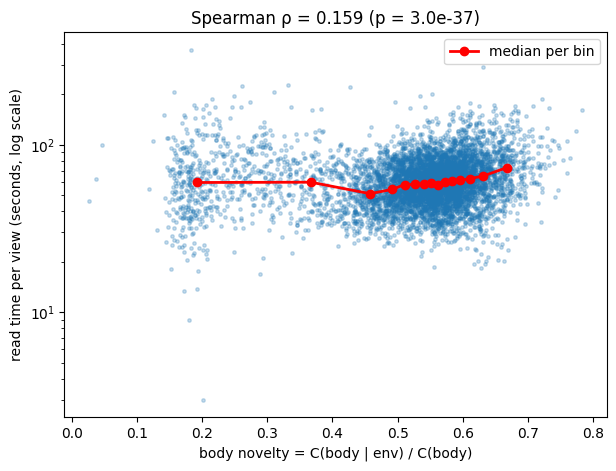

In [80]:
# --- Plot: read time per view vs body novelty ---
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df["novelty"], df["read_per_view"], s=6, alpha=0.25)

med = df.groupby(pd.qcut(df["novelty"], 15, duplicates="drop"), observed=True)[["novelty", "read_per_view"]].median()
ax.plot(med["novelty"], med["read_per_view"], color="red", lw=2, marker="o", label="median per bin")

rho, p = stats.spearmanr(df["novelty"], df["read_per_view"])
ax.set_yscale("log")
ax.set_xlabel("body novelty = C(body | env) / C(body)")
ax.set_ylabel("read time per view (seconds, log scale)")
ax.set_title(f"Spearman ρ = {rho:.3f} (p = {p:.1e})")
ax.legend()
plt.show()

Showing the corrolation beetween RPV and Length

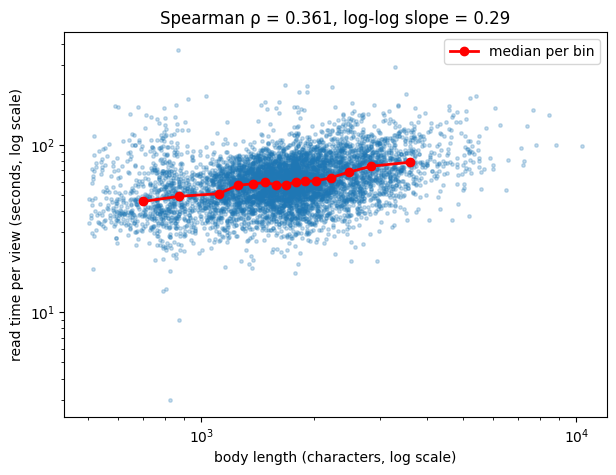

In [81]:
# --- Plot: read time per view vs body length ---
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df["body_len"], df["read_per_view"], s=6, alpha=0.25)

med = df.groupby(pd.qcut(df["body_len"], 15, duplicates="drop"), observed=True)[["body_len", "read_per_view"]].median()
ax.plot(med["body_len"], med["read_per_view"], color="red", lw=2, marker="o", label="median per bin")

# log-log slope: 1 = read time proportional to length, <1 = people read proportionally less of long articles
slope, intercept = np.polyfit(np.log(df["body_len"]), np.log(df["read_per_view"]), 1)

rho, p = stats.spearmanr(df["body_len"], df["read_per_view"])
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("body length (characters, log scale)")
ax.set_ylabel("read time per view (seconds, log scale)")
ax.set_title(f"Spearman ρ = {rho:.3f}, log-log slope = {slope:.2f}")
ax.legend()
plt.show()

Normalising

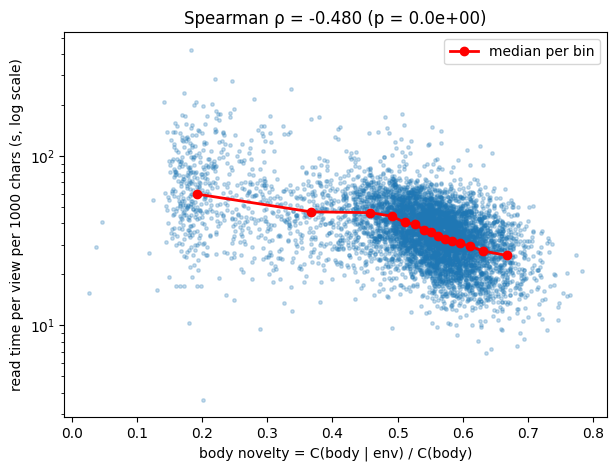

In [82]:
# --- Plot: read time per view per 1000 characters vs body novelty ---
df["read_per_kchar"] = df["read_per_view"] / (df["body_len"] / 1000)

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df["novelty"], df["read_per_kchar"], s=6, alpha=0.25)

med = df.groupby(pd.qcut(df["novelty"], 15, duplicates="drop"), observed=True)[["novelty", "read_per_kchar"]].median()
ax.plot(med["novelty"], med["read_per_kchar"], color="red", lw=2, marker="o", label="median per bin")

rho, p = stats.spearmanr(df["novelty"], df["read_per_kchar"])
ax.set_yscale("log")
ax.set_xlabel("body novelty = C(body | env) / C(body)")
ax.set_ylabel("read time per view per 1000 chars (s, log scale)")
ax.set_title(f"Spearman ρ = {rho:.3f} (p = {p:.1e})")
ax.legend()
plt.show()

In [83]:
x = np.log(df["body_len"])

# length-adjusted read time (residual of the log-log fit)
slope, intercept = np.polyfit(x, np.log(df["read_per_view"]), 1)
df["read_adj"] = np.log(df["read_per_view"]) - (intercept + slope * x)

# length-adjusted novelty
s_n, i_n = np.polyfit(x, df["novelty"], 1)
df["novelty_adj"] = df["novelty"] - (i_n + s_n * x)

print(stats.spearmanr(df["body_len"], df["read_adj"]))   # check: should be ~0
print(stats.spearmanr(df["novelty_adj"], df["read_adj"]))  # the partial correlation you want

SignificanceResult(statistic=0.017481925736424115, pvalue=0.16457843009494952)
SignificanceResult(statistic=-0.11279916644568065, pvalue=2.3468118244197904e-19)


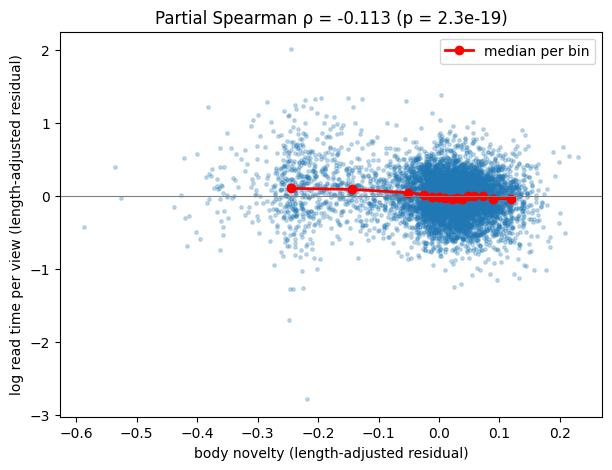

In [84]:
# --- Plot: length-adjusted read time vs length-adjusted novelty ---
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df["novelty_adj"], df["read_adj"], s=6, alpha=0.25)

med = df.groupby(pd.qcut(df["novelty_adj"], 15, duplicates="drop"), observed=True)[["novelty_adj", "read_adj"]].median()
ax.plot(med["novelty_adj"], med["read_adj"], color="red", lw=2, marker="o", label="median per bin")

rho, p = stats.spearmanr(df["novelty_adj"], df["read_adj"])
ax.set_xlabel("body novelty (length-adjusted residual)")
ax.set_ylabel("log read time per view (length-adjusted residual)")
ax.set_title(f"Partial Spearman ρ = {rho:.3f} (p = {p:.1e})")
ax.axhline(0, color="gray", lw=0.8)
ax.legend()
plt.show()

#### Why it does not work? Maybe it only work for some categories of news

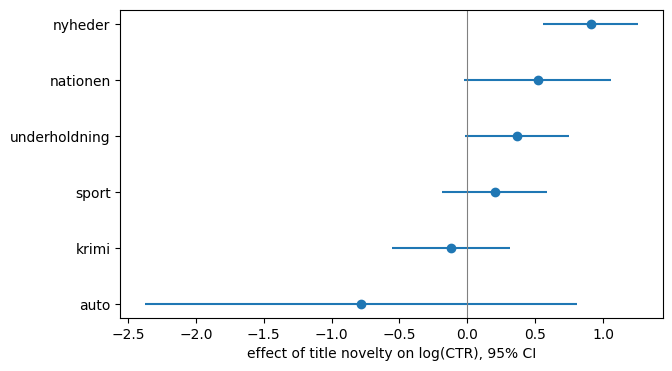

(1.8113382324128795, 0.1070082369576566, 5.0)


In [85]:
big = df["category_str"].value_counts()
big = big[big >= 200].index
d = df[df["category_str"].isin(big)]

# per-category effect with confidence intervals
rows = []
for cat, g in d.groupby("category_str"):
    m = smf.ols("np.log(ctr) ~ novelty_title + np.log(title_len) + np.log(env_chars)", data=g).fit(cov_type="HC3")
    lo, hi = m.conf_int().loc["novelty_title"]
    rows.append({"category": cat, "n": len(g), "coef": m.params["novelty_title"], "lo": lo, "hi": hi})
per_cat = pd.DataFrame(rows).sort_values("coef")

fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(per_cat["coef"], per_cat["category"], xerr=[per_cat["coef"] - per_cat["lo"], per_cat["hi"] - per_cat["coef"]], fmt="o")
ax.axvline(0, color="gray", lw=0.8)
ax.set_xlabel("effect of title novelty on log(CTR), 95% CI")
plt.show()

# formal heterogeneity test: does the effect differ across categories?
m0 = smf.ols("np.log(ctr) ~ novelty_title + np.log(title_len) + np.log(env_chars) + C(category_str)", data=d).fit()
m1 = smf.ols("np.log(ctr) ~ novelty_title * C(category_str) + np.log(title_len) + np.log(env_chars)", data=d).fit()
print(m1.compare_f_test(m0))   # (F, p, df): small p = effect really varies by category

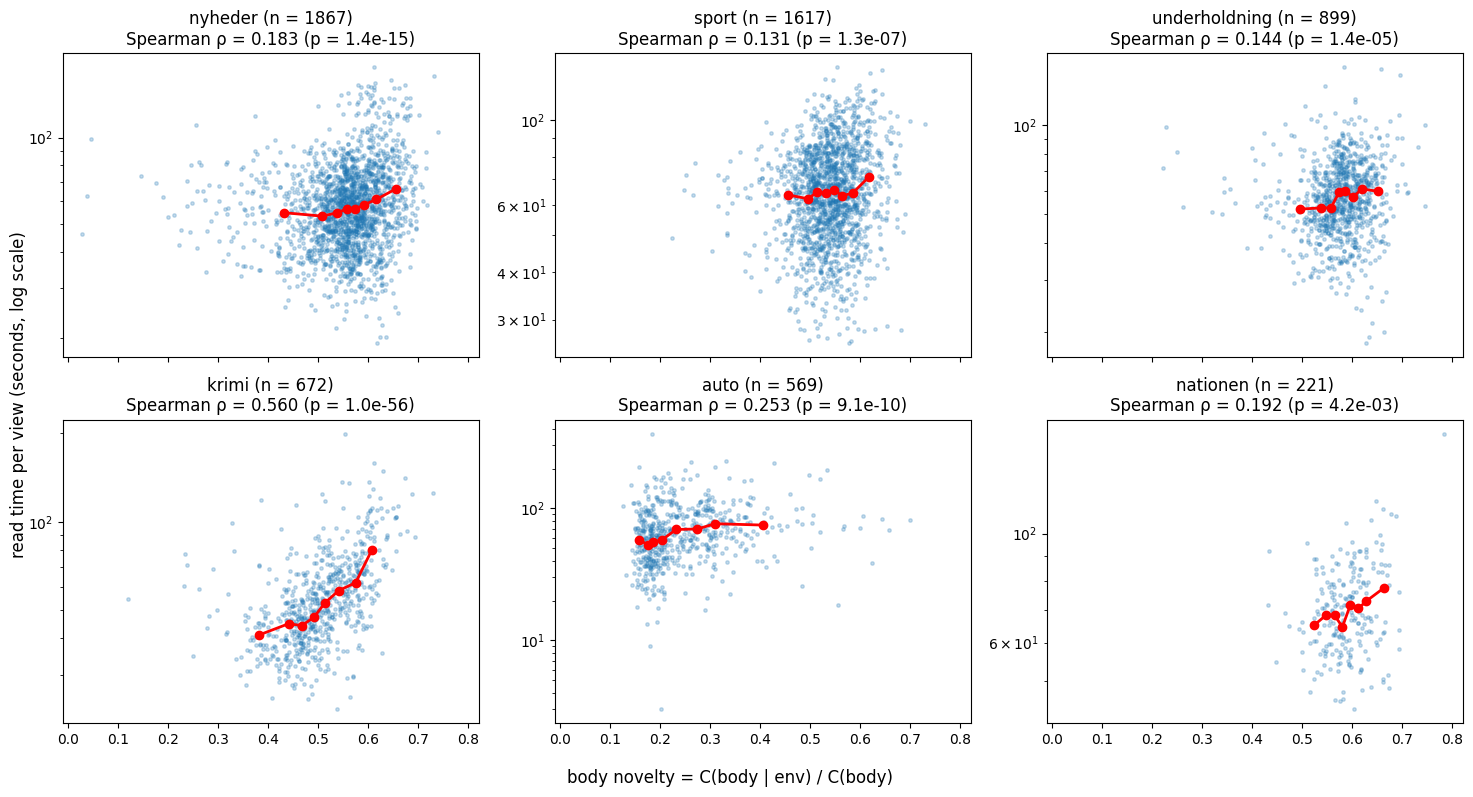

In [86]:
big = df["category_str"].value_counts()
big = big[big >= 200].index
d = df[df["novelty"].notna()]

ncols = 3
nrows = int(np.ceil(len(big) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows), sharex=True, sharey=False)
axes = axes.flatten()

for ax, cat in zip(axes, big):
    g = d[d["category_str"] == cat]
    ax.scatter(g["novelty"], g["read_per_view"], s=6, alpha=0.25)

    med = g.groupby(pd.qcut(g["novelty"], 8, duplicates="drop"), observed=True)[["novelty", "read_per_view"]].median()
    ax.plot(med["novelty"], med["read_per_view"], color="red", lw=2, marker="o")

    rho, p = stats.spearmanr(g["novelty"], g["read_per_view"])
    ax.set_yscale("log")
    ax.set_title(f"{cat} (n = {len(g)})\nSpearman ρ = {rho:.3f} (p = {p:.1e})")

for ax in axes[len(big):]:      # hide unused panels
    ax.set_visible(False)

fig.supxlabel("body novelty = C(body | env) / C(body)")
fig.supylabel("read time per view (seconds, log scale)")
plt.tight_layout()
plt.show()

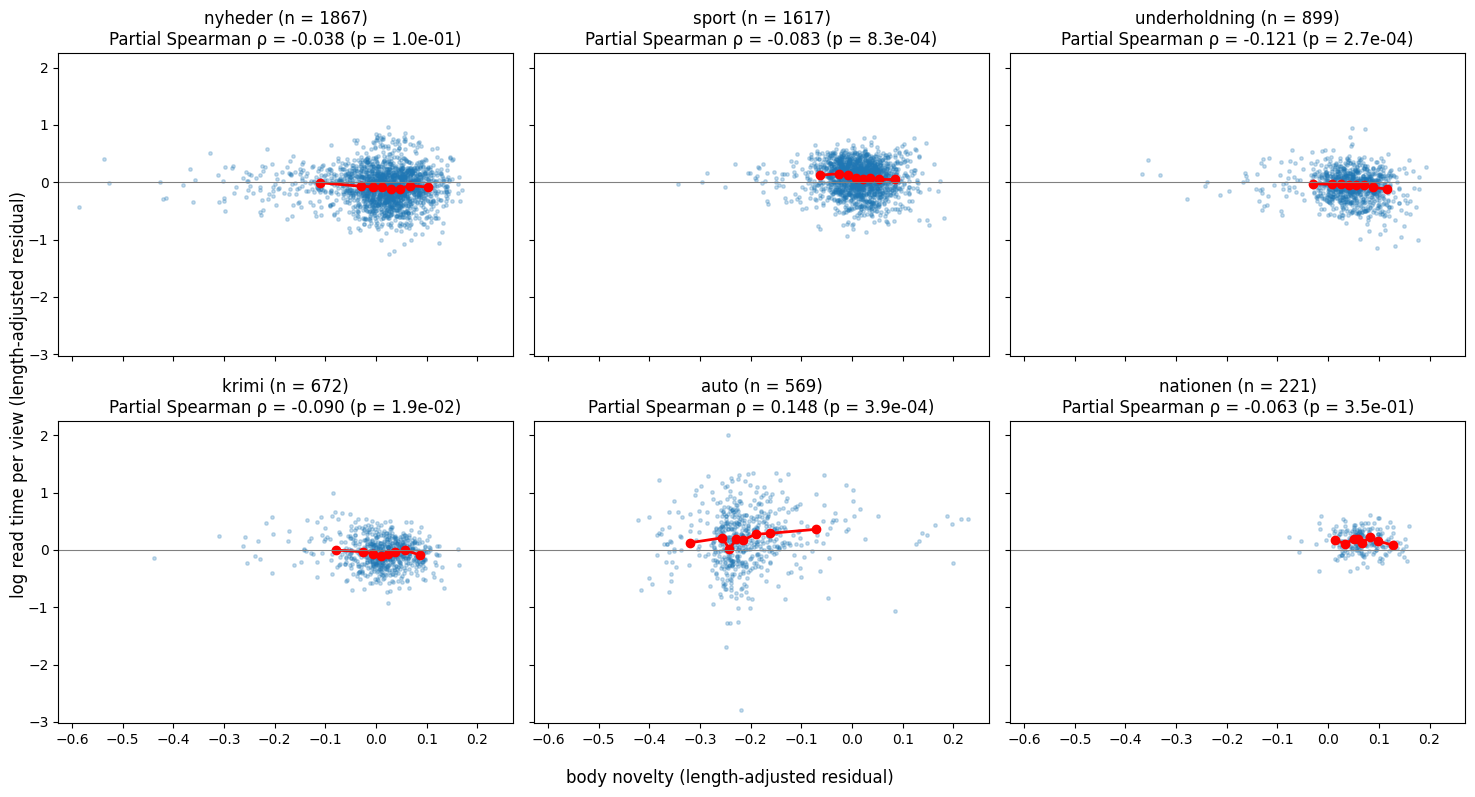

In [87]:
big = df["category_str"].value_counts()
big = big[big >= 200].index
d = df[df["novelty_adj"].notna()]

ncols = 3
nrows = int(np.ceil(len(big) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows), sharex=True, sharey=True)
axes = axes.flatten()

for ax, cat in zip(axes, big):
    g = d[d["category_str"] == cat]
    ax.scatter(g["novelty_adj"], g["read_adj"], s=6, alpha=0.25)

    med = g.groupby(pd.qcut(g["novelty_adj"], 8, duplicates="drop"), observed=True)[["novelty_adj", "read_adj"]].median()
    ax.plot(med["novelty_adj"], med["read_adj"], color="red", lw=2, marker="o")

    rho, p = stats.spearmanr(g["novelty_adj"], g["read_adj"])
    ax.axhline(0, color="gray", lw=0.8)
    ax.set_title(f"{cat} (n = {len(g)})\nPartial Spearman ρ = {rho:.3f} (p = {p:.1e})")

for ax in axes[len(big):]:      # hide unused panels
    ax.set_visible(False)

fig.supxlabel("body novelty (length-adjusted residual)")
fig.supylabel("log read time per view (length-adjusted residual)")
plt.tight_layout()
plt.show()

### NCD

In this part, we try to get better results by "densifying" the environment.

The idea is that having a huge environment design more a complexity that reflects the danish language and the writing style than the true content of the article. To solve that, we try to compare a given article with only one other article (the one that shares the more resemblance) so that our novelty measure makes more sense. To this purpose, we use the AIT tool : NCD to measure the proximity between 2 articles

In [88]:
@lru_cache(maxsize=None)
def cached_complexity(text: str, small_filter: bool = False) -> int:
    return complexity(text, small_filter)

def ncd(a: str, b: str) -> float:
    ca = cached_complexity(a, True)                  # cached: each article compressed once
    cb = cached_complexity(b, True)
    cab = complexity(a + " " + b, small_filter=True)  # NOT cached: each pair is unique
    return (cab - min(ca, cb)) / max(ca, cb)

def min_ncd(corpus, article_id, hours=48):
    body = corpus.body(article_id)
    env = corpus.env(article_id, hours)

    scores = [(ncd(body, e), eid) for eid, e in zip(env["article_id"], env["body"].fillna(""))]
    best_ncd, best_id = min(scores, key=lambda t: t[0], default=(float("nan"), None))

    return {"article_id": article_id,
            "min_ncd": best_ncd,
            "nearest_id": best_id}

In [89]:
first_article_id = toStudy_corpus["article_id"].iloc[0]
t0 = time.time(); print(min_ncd(corpus, first_article_id) ); print(time.time() - t0, "s")

{'article_id': 9637298, 'min_ncd': 0.8220720720720721, 'nearest_id': 9627332}
0.04711580276489258 s


In [90]:
rerun = False
if os.path.exists("res_ncd.parquet") and not rerun:
    res_bis = pd.read_parquet("res_ncd.parquet")
else:
    res_bis = pd.DataFrame([min_ncd(corpus, a) for a in tqdm(toStudy_corpus["article_id"])])
    res_bis.to_parquet("res_ncd.parquet")

In [91]:
res_bis = pd.read_parquet("res_ncd.parquet")
df = df.merge(res_bis, on="article_id", how="left")
print(df.shape)

(6322, 27)


### Result analysis

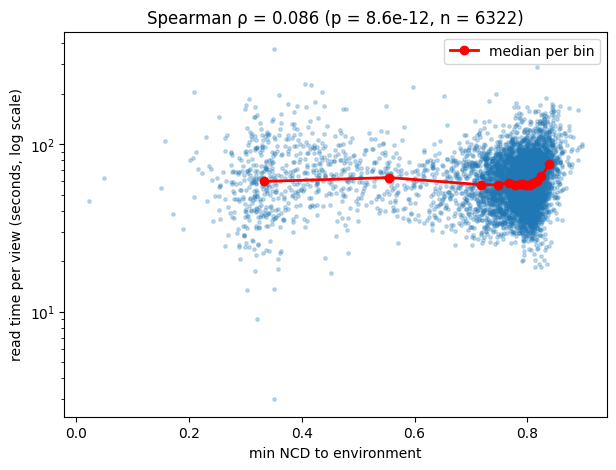

In [92]:
# --- Plot: raw read time per view vs min NCD ---
d = df[df["min_ncd"].notna()]

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(d["min_ncd"], d["read_per_view"], s=6, alpha=0.25)

med = d.groupby(pd.qcut(d["min_ncd"], 15, duplicates="drop"), observed=True)[["min_ncd", "read_per_view"]].median()
ax.plot(med["min_ncd"], med["read_per_view"], color="red", lw=2, marker="o", label="median per bin")

rho, p = stats.spearmanr(d["min_ncd"], d["read_per_view"])
ax.set_yscale("log")
ax.set_xlabel("min NCD to environment")
ax.set_ylabel("read time per view (seconds, log scale)")
ax.set_title(f"Spearman ρ = {rho:.3f} (p = {p:.1e}, n = {len(d)})")
ax.legend()
plt.show()

SignificanceResult(statistic=0.4485220621461143, pvalue=0.0)


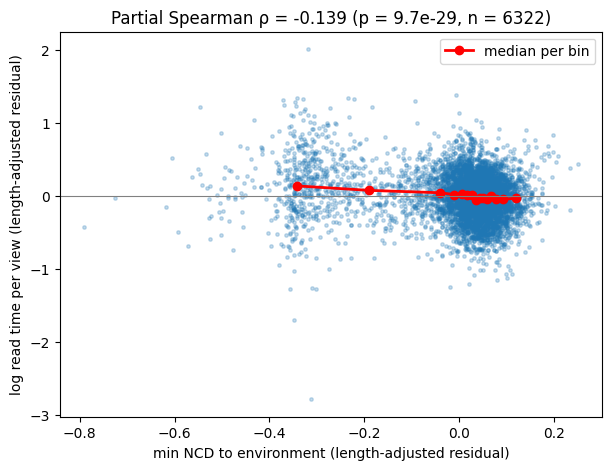

In [93]:
# --- length-adjusted min NCD ---
m = df["min_ncd"].notna()
x = np.log(df.loc[m, "body_len"])
s_c, i_c = np.polyfit(x, df.loc[m, "min_ncd"], 1)
df.loc[m, "min_ncd_adj"] = df.loc[m, "min_ncd"] - (i_c + s_c * x)

print(stats.spearmanr(df.loc[m, "body_len"], df.loc[m, "min_ncd"]))   # how much NCD depends on length

# --- Plot: length-adjusted read time vs length-adjusted min NCD ---
d = df[m]
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(d["min_ncd_adj"], d["read_adj"], s=6, alpha=0.25)

med = d.groupby(pd.qcut(d["min_ncd_adj"], 15, duplicates="drop"), observed=True)[["min_ncd_adj", "read_adj"]].median()
ax.plot(med["min_ncd_adj"], med["read_adj"], color="red", lw=2, marker="o", label="median per bin")

rho, p = stats.spearmanr(d["min_ncd_adj"], d["read_adj"])
ax.set_xlabel("min NCD to environment (length-adjusted residual)")
ax.set_ylabel("log read time per view (length-adjusted residual)")
ax.set_title(f"Partial Spearman ρ = {rho:.3f} (p = {p:.1e}, n = {len(d)})")
ax.axhline(0, color="gray", lw=0.8)
ax.legend()
plt.show()

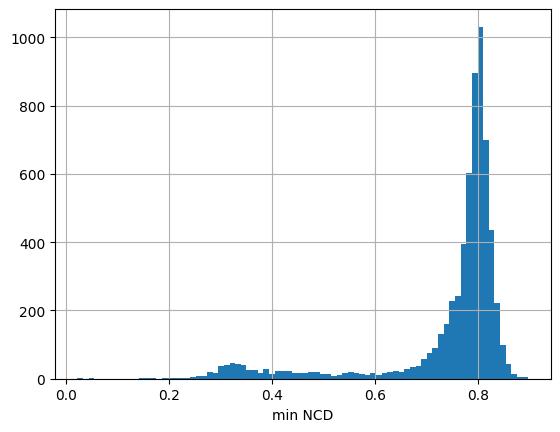

0.09854476431509016 623
                                                                               title                                                                              nearest_title   min_ncd   category_str
2731                   Overskuddet svundet ind med flere milliarder hos Koldingvej 2                  Veltec Industrial Services øger omsætningen med et trecifret millionbeløb  0.464543           auto
2290  Underskud hos Brugsen For Brædstrup og Omegn efter tilbagegang på millionbeløb       Tilbagegang på millionbeløb giver underskud hos Løgumkloster og Omegns Brugsforening  0.231644           auto
2977                          Donald Trump frifundet for voldtægt: Dømt for overgreb                                   Trump vidner ikke i civilsag om ærekrænkelse og voldtægt  0.430569        nyheder
2347                          Hvidbjerg Vinduet løfter sin værdi med flere millioner                    Underskud hos Eltel Networks efter tilbagegang på tocifret millionbe

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               read_adj   R-squared:                       0.101
Model:                            OLS   Adj. R-squared:                  0.098
Method:                 Least Squares   F-statistic:                     47.90
Date:                Sun, 08 Nov 2026   Prob (F-statistic):          5.49e-152
Time:                        23:55:27   Log-Likelihood:                -1448.3
No. Observations:                6322   AIC:                             2933.
Df Residuals:                    6304   BIC:                             3054.
Df Model:                          17                                         
Covariance Type:                  HC3                                         
=====================================================================================================
                                        coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------
Intercept                             0.0263      0.102      0.257      0.798      -0.174       0.227
has_close_pred[T.True]               -0.0111      0.030     -0.375      0.708      -0.069       0.047
C(category_str)[T.bibliotek]         -0.0979      0.152     -0.645      0.519      -0.395       0.199
C(category_str)[T.biler]             -0.1382      0.094     -1.472      0.141      -0.322       0.046
C(category_str)[T.ferie]             -0.0559      0.067     -0.834      0.404      -0.187       0.076
C(category_str)[T.forbrug]           -0.1994      0.044     -4.489      0.000      -0.286      -0.112
C(category_str)[T.haandvaerkeren]     0.1572      0.106      1.487      0.137      -0.050       0.364
C(category_str)[T.incoming]           0.1494      0.051      2.934      0.003       0.050       0.249
C(category_str)[T.krimi]             -0.2492      0.036     -7.019      0.000      -0.319      -0.180
C(category_str)[T.musik]             -0.3495      0.041     -8.431      0.000      -0.431      -0.268
C(category_str)[T.nationen]          -0.0384      0.037     -1.048      0.295      -0.110       0.033
C(category_str)[T.nyheder]           -0.2757      0.034     -8.019      0.000      -0.343      -0.208
C(category_str)[T.opinionen]          0.2971      0.071      4.179      0.000       0.158       0.436
C(category_str)[T.penge]             -0.3325      0.040     -8.250      0.000      -0.412      -0.254
C(category_str)[T.sex_og_samliv]     -0.0332      0.066     -0.505      0.614      -0.162       0.096
C(category_str)[T.sport]             -0.1346      0.035     -3.845      0.000      -0.203      -0.066
C(category_str)[T.underholdning]     -0.2665      0.035     -7.552      0.000      -0.336      -0.197
np.log(env_chars)                     0.0134      0.008      1.774      0.076      -0.001       0.028
==============================================================================
Omnibus:                      496.057   Durbin-Watson:                   1.889
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             2087.707
Skew:                          -0.283   Prob(JB):                         0.00
Kurtosis:                       5.758   Cond. No.                     1.03e+03
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity robust (HC3)
[2] The condition number is large, 1.03e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [94]:
# 1. Where is the gap? (raw NCD histogram)
df["min_ncd"].hist(bins=80); plt.xlabel("min NCD"); plt.show()

# 2. Define the close-predecessor group (adjust the threshold after looking at the histogram)
thr = df["min_ncd_adj"].quantile(0.0) if False else -0.2     # residual gap visible at ~ -0.2
df["has_close_pred"] = df["min_ncd_adj"] < thr
print(df["has_close_pred"].mean(), df["has_close_pred"].sum())

# 3. What are they? Pairs + categories
titles = corpus.df.set_index("article_id")["title"]
close = df[df["has_close_pred"]].assign(nearest_title=lambda d: d["nearest_id"].map(titles))
print(close[["title", "nearest_title", "min_ncd", "category_str"]].sample(15, random_state=0).to_string())
print(pd.crosstab(df["category_str"], df["has_close_pred"], normalize="columns").round(2))

# 4. Does the effect survive category + environment controls?
smf.ols("read_adj ~ has_close_pred + np.log(env_chars) + C(category_str)", data=df).fit(cov_type="HC3").summary()

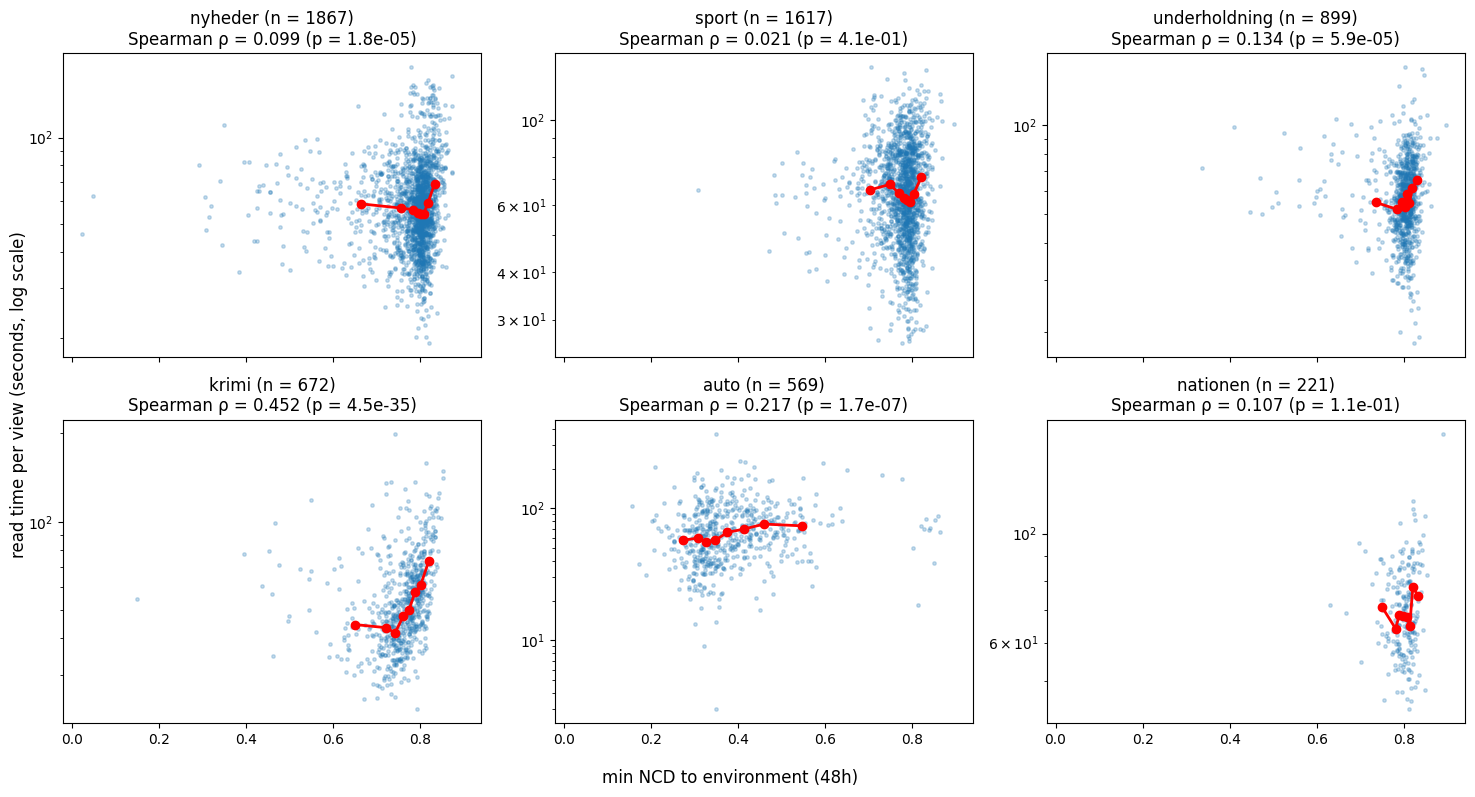

In [95]:
big = df["category_str"].value_counts()
big = big[big >= 200].index
d = df[df["min_ncd"].notna()]

ncols = 3
nrows = int(np.ceil(len(big) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows), sharex=True, sharey=False)
axes = axes.flatten()

for ax, cat in zip(axes, big):
    g = d[d["category_str"] == cat]
    ax.scatter(g["min_ncd"], g["read_per_view"], s=6, alpha=0.25)

    med = g.groupby(pd.qcut(g["min_ncd"], 8, duplicates="drop"), observed=True)[["min_ncd", "read_per_view"]].median()
    ax.plot(med["min_ncd"], med["read_per_view"], color="red", lw=2, marker="o")

    rho, p = stats.spearmanr(g["min_ncd"], g["read_per_view"])
    ax.set_yscale("log")
    ax.set_title(f"{cat} (n = {len(g)})\nSpearman ρ = {rho:.3f} (p = {p:.1e})")

for ax in axes[len(big):]:      # hide unused panels
    ax.set_visible(False)

fig.supxlabel("min NCD to environment (48h)")
fig.supylabel("read time per view (seconds, log scale)")
plt.tight_layout()
plt.show()

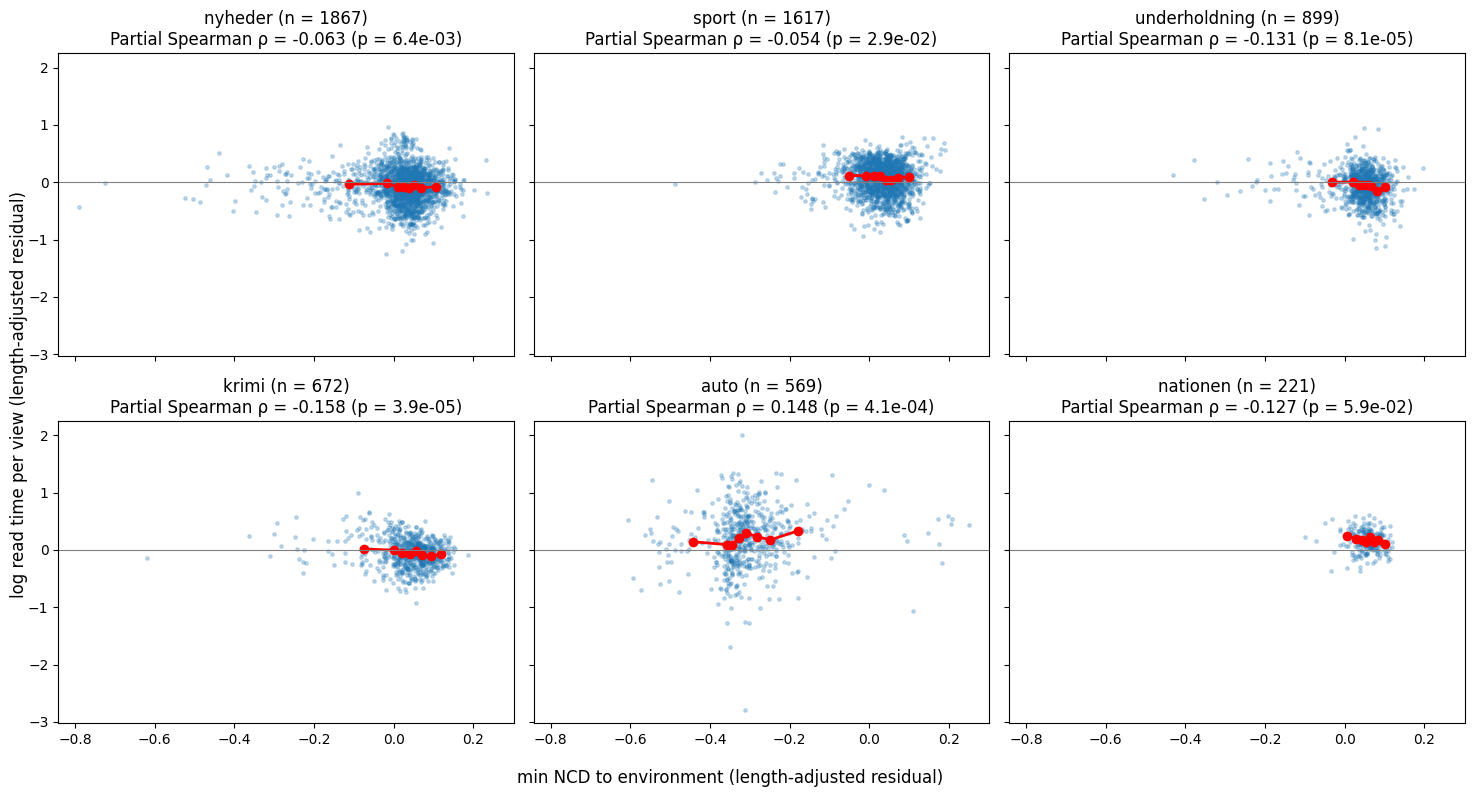

In [96]:
big = df["category_str"].value_counts()
big = big[big >= 200].index
d = df[df["min_ncd_adj"].notna()]

ncols = 3
nrows = int(np.ceil(len(big) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows), sharex=True, sharey=True)
axes = axes.flatten()

for ax, cat in zip(axes, big):
    g = d[d["category_str"] == cat]
    ax.scatter(g["min_ncd_adj"], g["read_adj"], s=6, alpha=0.25)

    med = g.groupby(pd.qcut(g["min_ncd_adj"], 8, duplicates="drop"), observed=True)[["min_ncd_adj", "read_adj"]].median()
    ax.plot(med["min_ncd_adj"], med["read_adj"], color="red", lw=2, marker="o")

    rho, p = stats.spearmanr(g["min_ncd_adj"], g["read_adj"])
    ax.axhline(0, color="gray", lw=0.8)
    ax.set_title(f"{cat} (n = {len(g)})\nPartial Spearman ρ = {rho:.3f} (p = {p:.1e})")

for ax in axes[len(big):]:      # hide unused panels
    ax.set_visible(False)

fig.supxlabel("min NCD to environment (length-adjusted residual)")
fig.supylabel("log read time per view (length-adjusted residual)")
plt.tight_layout()
plt.show()

### Detecting automatic generated content

In [99]:
y = df["category_str"] == "auto"
print("AUC min_ncd :", roc_auc_score(y, -df["min_ncd"]))
print("AUC novelty :", roc_auc_score(y, -df["novelty"]))

AUC min_ncd : 0.9777453927147965
AUC novelty : 0.9779163129376679


In [ ]:
info = corpus.df.set_index("article_id")

def show_pair(article_id, n_chars=400):
    row = df.loc[df["article_id"] == article_id].iloc[0]
    a, b = info.loc[article_id], info.loc[row["nearest_id"]]
    print(f"min NCD = {row['min_ncd']:.3f}")
    for label, aid, art in [("ARTICLE", article_id, a), ("NEAREST", row["nearest_id"], b)]:
        print(f"\n--- {label} {aid} | {art['category_str']} | auto = {art['category_str'] == 'auto'} | {art['published_time']}")
        print("TITLE:", art["title"])
        print("BODY :", (art["body"] or "")[:n_chars].replace("\n", " "), "...")
    print("\n" + "=" * 100 + "\n")

In [104]:
# the 3 closest pairs overall
for aid in df.nsmallest(10, "min_ncd")["article_id"]:
    show_pair(aid)

min NCD = 0.023

--- ARTICLE 9795462 | nyheder | auto = False | 2023-06-03 07:55:47
TITLE: Lader familier i stikken: Jeg er ikke stolt
BODY : Han lovede, at hjælpen til ville komme til foråret. Men selvom det officielt er blevet sommer, og politikerne snart går på lang sommerferie, har udlændinge- og integrationsminister Kaare Dybvad Bek (S) endnu ikke gennemført ændringerne af reglerne for familiesammenføring, som ellers har stået ' øverst på hans liste ' siden valget. Og nu lyder det i et interview med Ekstra Bladet, at han ikke engan ...

--- NEAREST 9791385 | nyheder | auto = False | 2023-06-03 07:40:12
TITLE: Lader familier i stikken: Jeg er ikke stolt
BODY : Han lovede, at hjælpen til ville komme til foråret. Men selvom det officielt er blevet sommer, og politikerne snart går på lang sommerferie, har udlændinge- og integrationsminister Kaare Dybvad Bek (S) endnu ikke gennemført ændringerne af reglerne for familiesammenføring, som ellers har stået 'øverst på hans liste' siden valg

In [103]:
close = df[df["min_ncd"] < 0.5]
show_pair(close.sample(1, random_state=None)["article_id"].iloc[0])

min NCD = 0.322

--- ARTICLE 9750626 | auto | auto = True | 2023-05-05 03:46:06
TITLE: Hus solgt dyrt på Ritmestervænget
BODY : I Ry, Skanderborg Kommune er et hus solgt for 5.550.000 kroner. Det giver en kvadratmeterpris på 31.534 kroner, hvilket er i den dyre ende for huse solgt i Ry. Ejendommen består af et fritliggende enfamiliehus på 176 kvadratmeter opført i 2019 samt en carport på 59 kvadratmeter opført i 2019 og et udhus på 10 kvadratmeter opført i 2020. Den ligger Ritmestervænget 6, 8680 Ry Køberne overtager juli  ...

--- NEAREST 9750557 | auto | auto = True | 2023-05-05 03:15:50
TITLE: Hus solgt dyrt på Jonshaven
BODY : I Slagelse er et hus solgt for 3.400.000 kroner. Det giver en kvadratmeterpris på 19.429 kroner, hvilket er i den dyre ende for huse solgt i Slagelse. Ejendommen består af et fritliggende enfamiliehus på 175 kvadratmeter opført i 2009. Adressen er Jonshaven 7, 4200 Slagelse De nye ejere overtog maj 2023 ejendommen. Købet blev aftalt marts 2023. Adresse Jonsha

### Using pretraitement

In [106]:
recent = art[art["published_time"] >= "2023-04-27"]
recent[["article_id", "title", "category_str", "ner_clusters", "entity_groups", "topics"]].head(10)

,article_id,title,category_str,ner_clusters,entity_groups,topics
4467,9647575,Kvinderne der kan sparke din røv!,underholdning,"[amerikaner, Black Lives Matter, Buffy the Vam...","[MISC, ORG, PROD, PER, PER, PER, ORG, PROD, PE...","[Kendt, Livsstil, Sport]"
4739,9667501,Advarsel! Bliv inden døre i år,musik,"[Adele, Albani, Amager, Aphex Twin, Beyoncé, B...","[PER, PER, LOC, PROD, ORG, ORG, PROD, PER, PER...","[Underholdning, Begivenhed, Musik og lyd, Unde..."
4988,9685759,Realitystjerner: - Sådan scorer du os,underholdning,"[Christel Trubka, Ex on the beach, Fitness, Ka...","[PER, PROD, PER, PER, PER, LOC, PER, ORG, PER,...","[Kendt, Livsstil, Underholdning, Reality]"
4991,9685856,Realitystjerner: Det tænder vi på,underholdning,"[Afrika, Ekstra Bladet, Fitness, Grand Prix, H...","[LOC, ORG, PER, EVENT, PER, PROD, MISC, PER, P...","[Kendt, Livsstil, Underholdning, Reality, Erotik]"
5049,9690920,Dansk og dødbringende,underholdning,"[Bruhn Newtech, C, D, Danmark, Dansk Industri,...","[ORG, LOC, LOC, LOC, ORG, ORG, ORG, ORG, PER, ...","[Erhverv, Kendt, Konflikt og krig, Teknologi, ..."
5330,9708667,Bitter konkurs: Mangler millioner,underholdning,"[Bro, Bro, Bro & Jasmin, Ekstra Bladet, Gældss...","[ORG, PER, PROD, ORG, ORG, PER, ORG]","[Kendt, Underholdning, Musik og lyd, Økonomi]"
5432,9714644,Savner et punktum: - Han har snydt mig for min...,krimi,"[Ansager, Britta Buhl, Brittas, Danmark, Dubai...","[LOC, PER, PER, LOC, LOC, ORG, ORG, ORG, LOC, ...","[Kriminalitet, Personfarlig kriminalitet]"
5465,9716107,Vineksperten: Flotte franske bobler uden for C...,forbrug,"[Alsace, Alsace, Anjou, Arbois, Bordeaux, Bour...","[LOC, PROD, LOC, PROD, LOC, LOC, PROD, LOC, PR...","[Livsstil, Mad og drikke]"
5478,9716537,- Simpelthen den værste opringning,krimi,"[Ekstra Bladet, København, Langebro, Ekstra Bl...","[ORG, LOC, LOC, ORG, LOC, LOC, PER]","[Kriminalitet, Kendt, Katastrofe, Mindre ulykke]"
5498,9717865,Hop øerne rundt,ferie,"[Ærø, Ærøs jord, Ærøskøbing Camping, Als, Anho...","[LOC, LOC, LOC, LOC, LOC, LOC, LOC, LOC, LOC, ...","[Kultur, Rejse]"


We try to use a tf-idf-like measure with the ner-entities to try to define a more accurate way to estimate novelty

First :  an environment-based approach (like novelty). We get the tf-idf of a given article in its environment.

In [109]:

# entity counts per article (lowercase, drop 1-char noise): the duplicates become term frequencies
ent_counts = art.set_index("article_id")["ner_clusters"].apply(
    lambda l: Counter(e.lower() for e in l if len(e) > 1) if l is not None else Counter())

N = len(ent_counts)
doc_freq = Counter(e for c in ent_counts for e in c)                 # in how many articles each entity appears
idf = {e: np.log2(N / d) for e, d in doc_freq.items()}               # information content, in bits

def tfidf_novelty(corpus, article_id, hours=48):
    own = ent_counts.get(article_id, Counter())
    if not own:
        return float("nan")
    seen = set().union(*[ent_counts.get(e, Counter()).keys() for e in corpus.env(article_id, hours)["article_id"]])
    w = {e: tf * idf[e] for e, tf in own.items()}                     # tf-idf weight of each entity
    return sum(v for e, v in w.items() if e not in seen) / sum(w.values())

df["tfidf_novelty"] = [tfidf_novelty(corpus, a) for a in tqdm(df["article_id"])]

  0%|          | 0/6322 [00:00<?, ?it/s]

In [110]:
def tfidf_vec(c):
    return {e: tf * idf[e] for e, tf in c.items()}

def cosine(u, v):
    num = sum(u[k] * v[k] for k in u.keys() & v.keys())
    den = math.sqrt(sum(x * x for x in u.values())) * math.sqrt(sum(x * x for x in v.values()))
    return num / den if den else 0.0

def max_tfidf_sim(corpus, article_id, hours=48):
    u = tfidf_vec(ent_counts.get(article_id, Counter()))
    if not u:
        return float("nan")
    sims = [cosine(u, tfidf_vec(ent_counts.get(e, Counter()))) for e in corpus.env(article_id, hours)["article_id"]]
    return max(sims, default=float("nan"))       # 1 = same entities as a recent article, 0 = nothing in common

df["max_tfidf_sim"] = [max_tfidf_sim(corpus, a) for a in tqdm(df["article_id"])]

  0%|          | 0/6322 [00:00<?, ?it/s]

### Result analysis

In [111]:
df["n_ents"] = df["article_id"].map(lambda a: len(ent_counts.get(a, {})))

measures = {"novelty_adj (form, global)":  "novelty_adj",
            "min_ncd_adj (form, pairwise)": "min_ncd_adj",
            "tfidf_novelty (content, global)": "tfidf_novelty",
            "max_tfidf_sim (content, pairwise)": "max_tfidf_sim"}

d = df[(df["category_str"] != "auto") & (df["n_ents"] > 0)]
rows = []
for label, col in measures.items():
    g = d.dropna(subset=[col, "read_adj"])
    m = smf.ols(f"read_adj ~ {col} + np.log(n_ents) + np.log(env_chars) + C(category_str)",
                data=g).fit(cov_type="HC3")
    lo, hi = m.conf_int().loc[col]
    rho, p = stats.spearmanr(g[col], g["read_adj"])
    rows.append({"measure": label, "n": len(g), "coef": m.params[col], "ci_low": lo, "ci_high": hi,
                 "p": m.pvalues[col], "spearman_rho": rho})
pd.DataFrame(rows).round(4)

,measure,n,coef,ci_low,ci_high,p,spearman_rho
0,"novelty_adj (form, global)",5736,-0.2349,-0.3569,-0.1128,0.0002,-0.0606
1,"min_ncd_adj (form, pairwise)",5736,-0.1944,-0.3023,-0.0865,0.0004,-0.0880
2,"tfidf_novelty (content, global)",5736,-0.1374,-0.1674,-0.1075,0.0000,-0.1304
3,"max_tfidf_sim (content, pairwise)",5736,0.1610,0.1167,0.2054,0.0000,0.1253


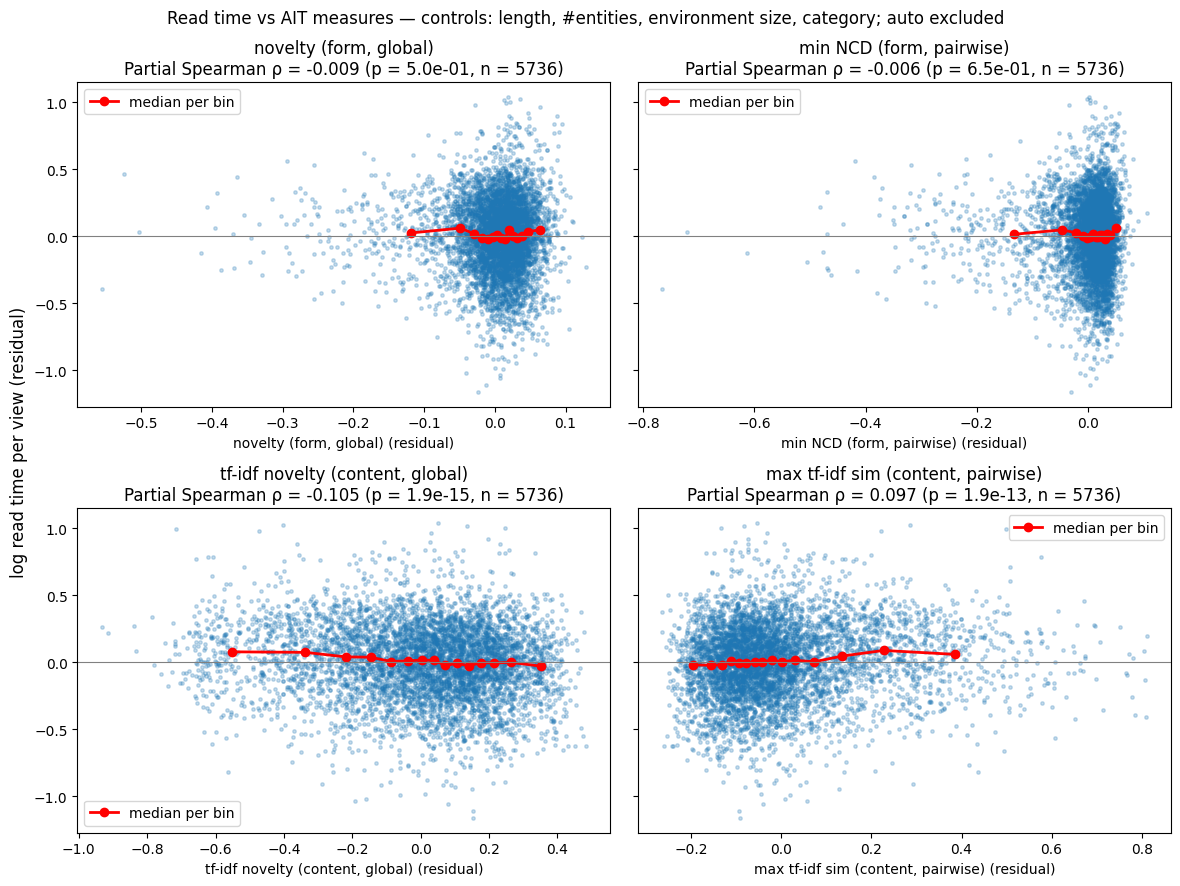

In [114]:

measures = {"novelty (form, global)":         "novelty",
            "min NCD (form, pairwise)":       "min_ncd",
            "tf-idf novelty (content, global)": "tfidf_novelty",
            "max tf-idf sim (content, pairwise)": "max_tfidf_sim"}

controls = "np.log(body_len) + np.log(n_ents) + np.log(env_chars) + C(category_str)"
d = df[(df["category_str"] != "auto") & (df["n_ents"] > 0)]

fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharey=True)
for ax, (label, col) in zip(axes.flatten(), measures.items()):
    g = d.dropna(subset=[col, "read_adj"]).copy()
    g["x_res"] = smf.ols(f"{col} ~ {controls}", data=g).fit().resid
    g["y_res"] = smf.ols(f"read_adj ~ {controls}", data=g).fit().resid

    ax.scatter(g["x_res"], g["y_res"], s=6, alpha=0.25)
    med = g.groupby(pd.qcut(g["x_res"], 15, duplicates="drop"), observed=True)[["x_res", "y_res"]].median()
    ax.plot(med["x_res"], med["y_res"], color="red", lw=2, marker="o", label="median per bin")

    rho, p = stats.spearmanr(g["x_res"], g["y_res"])
    ax.axhline(0, color="gray", lw=0.8)
    ax.set_xlabel(f"{label} (residual)")
    ax.set_title(f"{label}\nPartial Spearman ρ = {rho:.3f} (p = {p:.1e}, n = {len(g)})")
    ax.legend()

fig.supylabel("log read time per view (residual)")
fig.suptitle("Read time vs AIT measures — controls: length, #entities, environment size, category; auto excluded")
plt.tight_layout()
plt.show()

### Limitations

- We don't have access to a particuliar user environment. We probably tend to find what subject are read and what are not.